# การทำนายการคืนสินค้า (Product Return Classification)

**ประเภทปัญหา:** Supervised Classification  
**Target:** `returned` (0 = ไม่คืนสินค้า, 1 = คืนสินค้า)  
**ข้อมูลดิบ:** 1,062 records

โครงการนี้ศึกษาปัจจัยที่สัมพันธ์กับการคืนสินค้า เตรียมข้อมูล สำรวจข้อมูล เลือกคุณลักษณะ ฝึกเปรียบเทียบโมเดล classification และประเมินผลบนชุดทดสอบที่กันไว้ตั้งแต่ต้น

## 1. Problem Understanding และ Data Understanding

เป้าหมายคือทำนายว่า order จะถูกคืนหรือไม่ โดยใช้ราคา ระยะเวลาจัดส่ง คะแนนรีวิว ส่วนลด ลูกค้าซื้อซ้ำ และประเภทสินค้า ไม่ใช้ `order_id` เป็นตัวทำนายเพราะเป็นเพียง identifier

**สมมติฐานที่ใช้:** คะแนนรีวิวควรอยู่ในช่วง 1–5; ส่วนลดเป็นเปอร์เซ็นต์ 0–100; ราคาและวันจัดส่งต้องเป็นค่าบวก เราจะทำเครื่องหมายค่าที่ผิดขอบเขตเป็น missing และไม่ลบ outlier ที่ยังเป็นไปได้โดยไม่มีหลักฐานว่าเป็นข้อผิดพลาด

In [37]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

In [38]:

df = pd.read_csv("Lab10_Final_Project.csv")
print(f"ขนาดข้อมูล: {df.shape[0]:,} แถว x {df.shape[1]} คอลัมน์")
display(df.head())

ขนาดข้อมูล: 1,062 แถว x 8 คอลัมน์


,order_id,price,delivery_days,rating,discount_percent,repeat_customer,category,returned
0,O00715,2496.7,9.0,4.0,47.0,No,Fashion,0
1,O00700,1496.3,8.0,4.0,19.0,Yes,Fashion,0
2,O00673,1241.3,8.0,5.0,23.0,No,Home,0
3,O00017,1645.9,7.0,4.0,8.0,No,Home,0
4,O00528,921.4,12.0,1.0,41.0,Yes,Fashion,1


In [39]:
print("ชนิดข้อมูลและจำนวน non-null:")
df.info()

ชนิดข้อมูลและจำนวน non-null:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1062 entries, 0 to 1061
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          1062 non-null   object 
 1   price             1057 non-null   float64
 2   delivery_days     1056 non-null   float64
 3   rating            1058 non-null   float64
 4   discount_percent  1057 non-null   float64
 5   repeat_customer   1058 non-null   object 
 6   category          1056 non-null   object 
 7   returned          1062 non-null   int64  
dtypes: float64(4), int64(1), object(3)
memory usage: 66.5+ KB


In [40]:
print("จำนวน missing values:")
display(df.isna().sum().rename("missing_count").to_frame())

print(f"จำนวนแถวซ้ำทั้งหมด: {df.duplicated().sum()}")
print(f"จำนวน order_id ซ้ำ: {df['order_id'].duplicated().sum()}")

จำนวน missing values:


,missing_count
order_id,0
price,5
delivery_days,6
rating,4
discount_percent,5
repeat_customer,4
category,6
returned,0


จำนวนแถวซ้ำทั้งหมด: 12
จำนวน order_id ซ้ำ: 12


In [41]:
print("การกระจายของ target:")
display(df["returned"].value_counts(dropna=False).sort_index().rename_axis("returned").to_frame("count"))

การกระจายของ target:


,count
returned,
0,846
1,216


In [42]:
print("สถิติตัวแปรตัวเลข:")
display(df.select_dtypes(include="number").describe().T)

สถิติตัวแปรตัวเลข:


,count,mean,std,min,25%,50%,75%,max
price,1057.0,1300.242649,839.941769,100.0,610.60,1295.1,1853.4,4147.4
delivery_days,1056.0,6.585417,3.420115,1.0,3.75,7.0,9.0,12.0
rating,1058.0,3.047637,1.438937,1.0,2.00,3.0,4.0,8.0
discount_percent,1057.0,25.455818,14.638408,0.0,13.00,25.0,38.0,73.8
returned,1062.0,0.203390,0.402710,0.0,0.00,0.0,0.0,1.0


## 2. ตรวจ Shape, Data Type, Missing, Duplicate และ Outlier

ใช้ IQR ระบุ outlier เบื้องต้นเพื่อประกอบการตรวจสอบเท่านั้น ไม่ได้แปลว่าค่านั้นผิดเสมอไป การจัดการค่าผิดช่วงใช้ข้อกำหนดของโดเมน ไม่ใช้การลบ outlier อัตโนมัติ

In [43]:
numeric_features = ["price", "delivery_days", "rating", "discount_percent"]

print("IQR outlier candidates (ตรวจสอบ ไม่ลบอัตโนมัติ):")
outlier_rows = []
for column in numeric_features:
    values = pd.to_numeric(df[column], errors="coerce").dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_rows.append({
        "feature": column,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "candidate_count": int(((values < lower_bound) | (values > upper_bound)).sum()),
    })
display(pd.DataFrame(outlier_rows).set_index("feature"))

IQR outlier candidates (ตรวจสอบ ไม่ลบอัตโนมัติ):


,lower_bound,upper_bound,candidate_count
feature,,,
price,-1253.600,3717.600,3
delivery_days,-4.125,16.875,0
rating,-1.000,7.000,2
discount_percent,-24.500,75.500,0


In [44]:
print("ค่าคะแนนรีวิวที่พบ:")
print(sorted(df["rating"].dropna().unique()))

print("\nค่าหมวดหมู่ก่อน normalize:")
print("category:", sorted(df["category"].dropna().astype(str).unique()))
print("\nrepeat_customer:", sorted(df["repeat_customer"].dropna().astype(str).unique()))

ค่าคะแนนรีวิวที่พบ:
[np.float64(1.0), np.float64(1.6), np.float64(2.0), np.float64(3.0), np.float64(3.6), np.float64(4.0), np.float64(5.0), np.float64(7.2), np.float64(8.0)]

ค่าหมวดหมู่ก่อน normalize:
category: [' Home ', 'ELECTRONICS', 'Electronics', 'FASHION', 'Fashion', 'Home', 'electronics', 'home']

repeat_customer: [' Yes ', 'NO', 'No', 'YES', 'Yes', 'no', 'yes']


## 3. Data Cleaning

ลบรายการซ้ำโดยใช้ `order_id` (ข้อมูลตรวจแล้วว่า ID ซ้ำเป็นแถวเดียวกันจริง) ปรับข้อความ category/ลูกค้าซื้อซ้ำให้เป็นมาตรฐาน และเปลี่ยนค่าตัวเลขที่ผิดข้อกำหนดโดเมนเป็น missing เพื่อให้เติมค่าจากชุด train ภายใน preprocessing pipeline

In [45]:
rows_before_dedup = len(df)
df.drop_duplicates(subset="order_id", keep="first", inplace=True)
df.reset_index(drop=True, inplace=True)
rows_removed = rows_before_dedup - len(df)
print(f"ลบแถวซ้ำ: {rows_removed}")

ลบแถวซ้ำ: 12


In [46]:
for column in numeric_features:
    df[column] = pd.to_numeric(df[column], errors="coerce")

invalid_ranges = {
    "price": df["price"].notna() & (df["price"] <= 0),
    "delivery_days": df["delivery_days"].notna() & (df["delivery_days"] <= 0),
    "rating": df["rating"].notna() & ~df["rating"].between(1, 5),
    "discount_percent": df["discount_percent"].notna()
    & ~df["discount_percent"].between(0, 100),
}

# 1. Print จำนวนค่าที่ผิดปกติก่อนทำการแทนค่าด้วย NaN
invalid_counts = {column: int(mask.sum()) for column, mask in invalid_ranges.items()}
print("=== ก่อนจัดการค่าผิดปกติ (จำนวนข้อมูลที่ผิดเงื่อนไขโดเมน) ===")
for column, count in invalid_counts.items():
    print(f"คอลัมน์ '{column}': พบค่าผิดปกติ {count} แถว")

# ทำการแทนค่าที่ผิดปกติด้วย NaN
for column, mask in invalid_ranges.items():
    df.loc[mask, column] = np.nan

# 2. Print จำนวน Missing Values (NaN) หลังแทนค่าเสร็จแล้ว
print("\n=== หลังจัดการค่าผิดปกติ (จำนวน missing values รวมทั้งหมด) ===")
for column in numeric_features:
    nan_count = df[column].isna().sum()
    print(f"คอลัมน์ '{column}': มีค่า NaN ทั้งหมด {nan_count} แถว")

=== ก่อนจัดการค่าผิดปกติ (จำนวนข้อมูลที่ผิดเงื่อนไขโดเมน) ===
คอลัมน์ 'price': พบค่าผิดปกติ 0 แถว
คอลัมน์ 'delivery_days': พบค่าผิดปกติ 0 แถว
คอลัมน์ 'rating': พบค่าผิดปกติ 2 แถว
คอลัมน์ 'discount_percent': พบค่าผิดปกติ 0 แถว

=== หลังจัดการค่าผิดปกติ (จำนวน missing values รวมทั้งหมด) ===
คอลัมน์ 'price': มีค่า NaN ทั้งหมด 5 แถว
คอลัมน์ 'delivery_days': มีค่า NaN ทั้งหมด 6 แถว
คอลัมน์ 'rating': มีค่า NaN ทั้งหมด 6 แถว
คอลัมน์ 'discount_percent': มีค่า NaN ทั้งหมด 4 แถว


In [47]:
category_map = {"electronics": "Electronics", "home": "Home", "fashion": "Fashion"}
repeat_map = {"yes": "Yes", "y": "Yes", "no": "No", "n": "No"}

df["category"] = (
    df["category"].astype("string").str.strip().str.lower().map(category_map)
)
df["repeat_customer"] = (
    df["repeat_customer"].astype("string").str.strip().str.lower().map(repeat_map)
)

if not set(df["returned"].dropna().unique()).issubset({0, 1}):
    raise ValueError("Target returned ต้องมีค่า 0 หรือ 1 เท่านั้น")
if df["returned"].isna().any():
    raise ValueError("Target returned มี missing values จึงต้องตรวจสอบก่อนฝึกโมเดล")

display(df.head())

,order_id,price,delivery_days,rating,discount_percent,repeat_customer,category,returned
0,O00715,2496.7,9.0,4.0,47.0,No,Fashion,0
1,O00700,1496.3,8.0,4.0,19.0,Yes,Fashion,0
2,O00673,1241.3,8.0,5.0,23.0,No,Home,0
3,O00017,1645.9,7.0,4.0,8.0,No,Home,0
4,O00528,921.4,12.0,1.0,41.0,Yes,Fashion,1


In [48]:
print("ค่าตัวเลขที่ผิดช่วงและแทนเป็น missing:", invalid_counts)
print("Missing หลัง cleaning (ก่อน imputation):")
display(df.isna().sum().rename("missing_count").to_frame())
print(f"ขนาดข้อมูลหลัง cleaning: {df.shape[0]:,} แถว x {df.shape[1]} คอลัมน์")

ค่าตัวเลขที่ผิดช่วงและแทนเป็น missing: {'price': 0, 'delivery_days': 0, 'rating': 2, 'discount_percent': 0}
Missing หลัง cleaning (ก่อน imputation):


,missing_count
order_id,0
price,5
delivery_days,6
rating,6
discount_percent,4
repeat_customer,4
category,5
returned,0


ขนาดข้อมูลหลัง cleaning: 1,050 แถว x 8 คอลัมน์


## 4. EDA และ Visualization

กราฟด้านล่างช่วยดู class imbalance, ความแตกต่างของอัตราคืนระหว่างหมวดหมู่ และความสัมพันธ์ระหว่างจำนวนวันจัดส่งกับการคืนสินค้า (อัตราคืนเป็น descriptive เท่านั้น ไม่ใช่หลักฐานเชิงเหตุและผล)

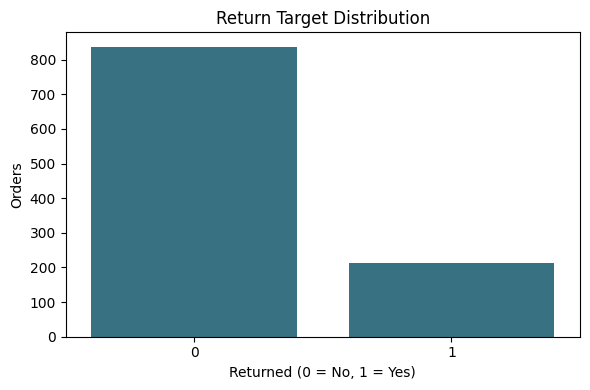

In [49]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df, x="returned", ax=ax, color="#2a788e")
ax.set_title("Return Target Distribution")
ax.set_xlabel("Returned (0 = No, 1 = Yes)")
ax.set_ylabel("Orders")
plt.tight_layout()
plt.show()

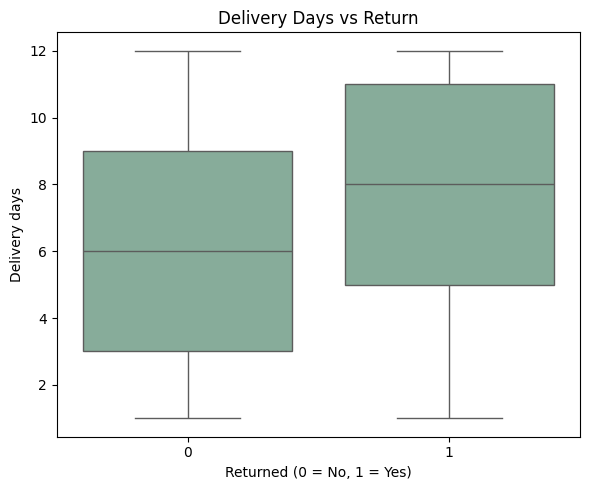

In [50]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.boxplot(data=df, x="returned", y="delivery_days", ax=ax, color="#81b29a")
ax.set_title("Delivery Days vs Return")
ax.set_xlabel("Returned (0 = No, 1 = Yes)")
ax.set_ylabel("Delivery days")
plt.tight_layout()
plt.show()

## 5. Transformation, Encoding, Feature Selection และตัด Identifier

เลือก predictor ที่เกี่ยวข้องและตัด `order_id` ออก แบ่ง train/test แบบ stratified ก่อนเรียนรู้ค่าทดแทน missing, one-hot encoding และ StandardScaler เพื่อป้องกันข้อมูลจาก test set รั่วเข้า training จากนั้นเลือก 8 features ที่มี Mutual Information สูงสุด (หรือน้อยกว่านั้นถ้าจำนวนฟีเจอร์มีไม่ถึง 8) โดยคำนวณจาก train set เท่านั้น

In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

categorical_features = ["category", "repeat_customer"]
feature_columns = numeric_features + categorical_features
X = df[feature_columns].copy()
y = df["returned"].astype(int)

print("ตัด identifier ออกจาก predictors:", "order_id" not in X.columns)
print("Features ก่อน preprocessing:", feature_columns)
print("สัดส่วน target ก่อนแบ่งชุด:")
display(y.value_counts(normalize=True).sort_index().rename("proportion").to_frame())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

ตัด identifier ออกจาก predictors: True
Features ก่อน preprocessing: ['price', 'delivery_days', 'rating', 'discount_percent', 'category', 'repeat_customer']
สัดส่วน target ก่อนแบ่งชุด:


,proportion
returned,
0,0.797143
1,0.202857


In [52]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)
transformed_feature_names = preprocessor.get_feature_names_out()
print(f"Preprocessed train shape: {X_train_processed.shape}")
print(f"Preprocessed test shape: {X_test_processed.shape}")

Preprocessed train shape: (840, 9)
Preprocessed test shape: (210, 9)


In [53]:
feature_selector = SelectKBest(
    score_func=lambda features, target: mutual_info_classif(
        features, target, random_state=42
    ),
    k=min(8, X_train_processed.shape[1]),
)
X_train_selected = feature_selector.fit_transform(X_train_processed, y_train)
X_test_selected = feature_selector.transform(X_test_processed)
selected_features = transformed_feature_names[feature_selector.get_support()]

selection_scores = pd.DataFrame({
    "feature": transformed_feature_names,
    "mutual_information": feature_selector.scores_,
    "selected": feature_selector.get_support(),
}).sort_values("mutual_information", ascending=False)
print(f"Selected {len(selected_features)} of {len(transformed_feature_names)} encoded features:")
display(selection_scores)

Selected 8 of 9 encoded features:


,feature,mutual_information,selected
5,categorical__category_Fashion,0.039761,True
2,numeric__rating,0.030688,True
8,categorical__repeat_customer_Yes,0.021680,True
0,numeric__price,0.013281,True
3,numeric__discount_percent,0.011867,True
4,categorical__category_Electronics,0.009705,True
6,categorical__category_Home,0.006646,True
7,categorical__repeat_customer_No,0.003104,True
1,numeric__delivery_days,0.000000,False


###  6. การค้นหาไฮเปอร์พารามิเตอร์แบบ Grid Search พร้อมกับทำ Cross-Validation ภายใน Pipeline

In [54]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score

# 1. กำหนดระบบ Cross-Validation (5-Fold Stratified CV)
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# 2. กำหนด Parameter Grid สำหรับโมเดลที่จะใช้
log_reg_grid = {
    'C': [0.01, 0.1, 1.0, 10.0, 100.0],
    'penalty': ['l2'],
    'solver': ['lbfgs', 'saga']
}

rf_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 8, 12],
    'min_samples_leaf': [2, 4, 6],
    'class_weight': ['balanced', None]
}

# 3. รัน Grid Search เพื่อหาพารามิเตอร์ที่ดีที่สุดโดยตรงบน Features ที่ผ่านการคัดเลือกแล้ว
tuned_models = {}

print("--- เริ่มจูน Logistic Regression ---")
grid_log_reg = GridSearchCV(
    estimator=LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42),
    param_grid=log_reg_grid,
    scoring='f1',
    cv=cv_strategy,
    n_jobs=-1
)
grid_log_reg.fit(X_train_selected, y_train)
tuned_models["Tuned Logistic Regression"] = grid_log_reg.best_estimator_
print(f"Best Params: {grid_log_reg.best_params_}")

print("\n--- เริ่มจูน Random Forest ---")
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_grid,
    scoring='f1',
    cv=cv_strategy,
    n_jobs=-1
)
grid_rf.fit(X_train_selected, y_train)
tuned_models["Tuned Random Forest"] = grid_rf.best_estimator_
print(f"Best Params: {grid_rf.best_params_}")

--- เริ่มจูน Logistic Regression ---
Best Params: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}

--- เริ่มจูน Random Forest ---
Best Params: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 6, 'n_estimators': 100}


In [55]:
# 4. ประเมินและแสดงผลลัพธ์ของโมเดลที่ปรับแต่งแล้วเทียบกับ Test Set
tuned_metric_rows = []
for model_name, model in tuned_models.items():
    predictions = model.predict(X_test_selected)
    tuned_metric_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (returned=1)": precision_score(y_test, predictions, pos_label=1, zero_division=0),
        "Recall (returned=1)": recall_score(y_test, predictions, pos_label=1, zero_division=0),
        "F1 (returned=1)": f1_score(y_test, predictions, pos_label=1, zero_division=0),
    })

tuned_results = pd.DataFrame(tuned_metric_rows).set_index("Model")
display(tuned_results.style.format("{:.3f}"))

,Accuracy,Precision (returned=1),Recall (returned=1),F1 (returned=1)
Model,,,,
Tuned Logistic Regression,0.705,0.373,0.651,0.475
Tuned Random Forest,0.719,0.346,0.419,0.379


## 7.  การประเมินโมเดล

In [56]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=8,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
}

model_predictions = {}
metric_rows = []
for model_name, model in models.items():
    model.fit(X_train_selected, y_train)
    predictions = model.predict(X_test_selected)
    model_predictions[model_name] = predictions
    metric_rows.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (returned=1)": precision_score(y_test, predictions, pos_label=1, zero_division=0),
        "Recall (returned=1)": recall_score(y_test, predictions, pos_label=1, zero_division=0),
        "F1 (returned=1)": f1_score(y_test, predictions, pos_label=1, zero_division=0),
    })

results = pd.DataFrame(metric_rows).set_index("Model").sort_values(
    "F1 (returned=1)", ascending=False
)
print("ผลประเมินบน test set (positive class = returned 1):")
display(results.style.format("{:.3f}"))

ผลประเมินบน test set (positive class = returned 1):


,Accuracy,Precision (returned=1),Recall (returned=1),F1 (returned=1)
Model,,,,
Logistic Regression,0.710,0.371,0.605,0.460
Random Forest,0.748,0.344,0.256,0.293


In [57]:
from sklearn.metrics import classification_report

for model_name, predictions in model_predictions.items():
    print(f"\n{model_name} - Classification Report")
    print(classification_report(
        y_test,
        predictions,
        labels=[0, 1],
        target_names=["Not returned (0)", "Returned (1)"],
        zero_division=0,
    ))


Logistic Regression - Classification Report
                  precision    recall  f1-score   support

Not returned (0)       0.88      0.74      0.80       167
    Returned (1)       0.37      0.60      0.46        43

        accuracy                           0.71       210
       macro avg       0.62      0.67      0.63       210
    weighted avg       0.77      0.71      0.73       210


Random Forest - Classification Report
                  precision    recall  f1-score   support

Not returned (0)       0.82      0.87      0.85       167
    Returned (1)       0.34      0.26      0.29        43

        accuracy                           0.75       210
       macro avg       0.58      0.57      0.57       210
    weighted avg       0.72      0.75      0.73       210



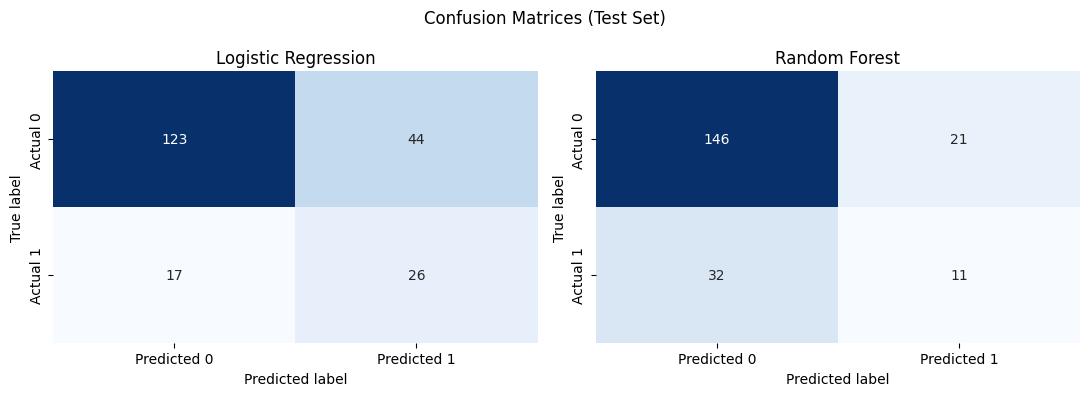

In [58]:
fig, axes = plt.subplots(1, len(model_predictions), figsize=(11, 4))
if len(model_predictions) == 1:
    axes = [axes]

for axis, (model_name, predictions) in zip(axes, model_predictions.items()):
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1])
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=axis,
    )
    axis.set_title(model_name)
    axis.set_xlabel("Predicted label")
    axis.set_ylabel("True label")

plt.suptitle("Confusion Matrices (Test Set)")
plt.tight_layout()
plt.show()

7.1 กราฟเปรียบเทียบประสิทธิภาพของทั้งสองโมเดล
เปรียบเทียบตัวชี้วัด (Accuracy, Precision, Recall, F1-score) บนชุดทดสอบระหว่าง Logistic Regression และ Random Forest

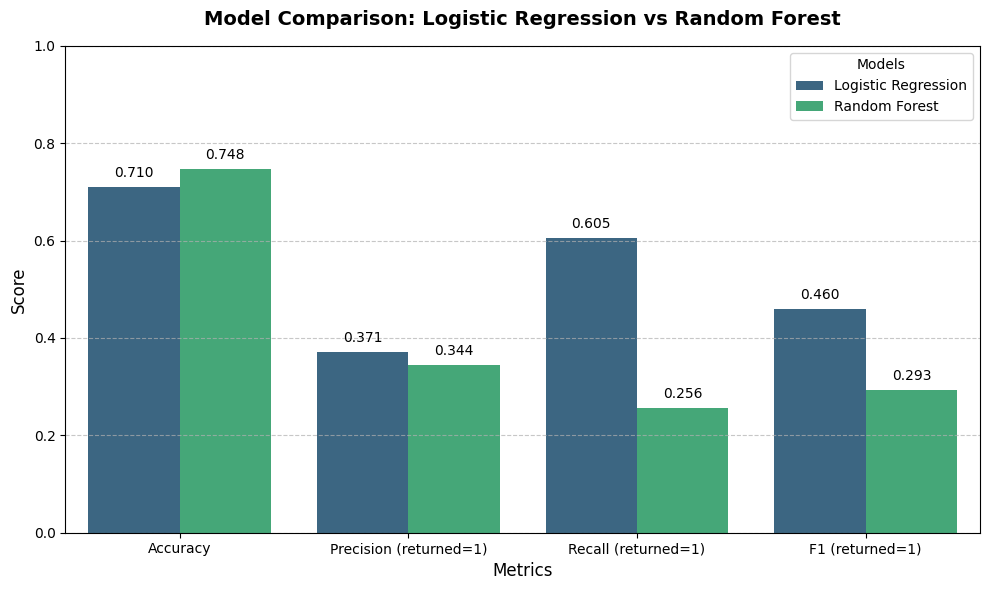

In [59]:
# แปลงตารางผลลัพธ์ให้อยู่ในรูปแบบที่วาดกราฟง่ายขึ้น (Melt DataFrame)
df_plot = results.reset_index().melt(id_vars="Model", var_name="Metric", value_name="Value")

plt.figure(figsize=(10, 6))
sns.barplot(data=df_plot, x="Metric", y="Value", hue="Model", palette="viridis")

plt.title("Model Comparison: Logistic Regression vs Random Forest", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Metrics", fontsize=12)
plt.ylabel("Score", fontsize=12)
plt.ylim(0, 1.0)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.legend(title="Models", loc="upper right")

# แสดงตัวเลขบนแท่งกราฟ
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f"{height:.3f}",
                            (p.get_x() + p.get_width() / 2., height),
                            ha="center", va="bottom",
                            fontsize=10, color="black",
                            xytext=(0, 5),
                            textcoords="offset points")

plt.tight_layout()
plt.show()

## 8. สรุปผลและข้อจำกัด

เลือกโมเดลจาก F1-score ของกลุ่มคืนสินค้า เพราะข้อมูลมี class imbalance; ควรพิจารณา Recall และ Confusion Matrix ควบคู่กันตามต้นทุนของการพลาดผู้มีแนวโน้มคืนสินค้า ผลจากข้อมูลนี้ใช้ประเมินความสามารถในการทำนาย ไม่ยืนยันความเป็นเหตุเป็นผล

In [60]:
best_model_name = results.index[0]
best_metrics = results.loc[best_model_name]
print(f"โมเดลที่ได้ F1-score สำหรับ returned=1 สูงสุด: {best_model_name}")
print(
    f"Accuracy={best_metrics['Accuracy']:.3f}, "
    f"Precision={best_metrics['Precision (returned=1)']:.3f}, "
    f"Recall={best_metrics['Recall (returned=1)']:.3f}, "
    f"F1={best_metrics['F1 (returned=1)']:.3f}"
)
print(
    "ข้อควรระวัง: คะแนนประเมินมาจาก test set ชุดเดียวและข้อมูลมี class imbalance; "
    "ควรยืนยันผลด้วย cross-validation หรือข้อมูลใหม่ก่อนนำไปใช้งานจริง"
)

โมเดลที่ได้ F1-score สำหรับ returned=1 สูงสุด: Logistic Regression
Accuracy=0.710, Precision=0.371, Recall=0.605, F1=0.460
ข้อควรระวัง: คะแนนประเมินมาจาก test set ชุดเดียวและข้อมูลมี class imbalance; ควรยืนยันผลด้วย cross-validation หรือข้อมูลใหม่ก่อนนำไปใช้งานจริง


In [63]:
import joblib

# บันทึกโมเดลที่ผ่านการจูนเรียบร้อยแล้วลงไฟล์
joblib.dump(tuned_models["Tuned Logistic Regression"], "best_logistic_regression.joblib")
joblib.dump(tuned_models["Tuned Random Forest"], "best_random_forest.joblib")


print("บันทึกโมเดลและขั้นตอนการเตรียมข้อมูลสำเร็จเรียบร้อย!")
print("- best_logistic_regression.joblib")
print("- best_random_forest.joblib\n")

print(f"โมเดลที่ได้ F1-score สำหรับ returned=1 สูงสุด: {best_model_name}")

บันทึกโมเดลและขั้นตอนการเตรียมข้อมูลสำเร็จเรียบร้อย!
- best_logistic_regression.joblib
- best_random_forest.joblib

โมเดลที่ได้ F1-score สำหรับ returned=1 สูงสุด: Logistic Regression
